# 逻辑回归建模案例

|字段名|中文含义|
|:--:|:--:|
|id|id|
|Acc|是否开卡(1=已开通)|
|avg_exp|月均信用卡支出（元）|
|avg_exp_ln|月均信用卡支出的自然对数|
|gender|性别(男=1)|
|Age|年龄|
|Income|年收入（万元）|
|Ownrent|是否自有住房（有=1；无=0)|
|Selfempl|是否自谋职业(1=yes, 0=no)|
|dist_home_val|所住小区房屋均价(万元)|
|dist_avg_income|当地人均收入|
|high_avg|高出当地平均收入|
|edu_class|教育等级：小学及以下开通=0，中学=1，本科=2，研究生=3|

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf
import os

pd.set_option('display.max_columns', 8)

In [2]:
data = pd.read_csv(r'creditcard_exp.csv', skipinitialspace=True)
data.head()

,id,Acc,avg_exp,avg_exp_ln,...,dist_avg_income,age2,high_avg,edu_class
0,19,1,1217.03,7.104169,...,15.932789,1600,0.102361,3
1,5,1,1251.50,7.132098,...,15.796316,1024,0.051184,2
2,95,0,NaN,NaN,...,7.490000,1296,0.910000,1
3,86,1,856.57,6.752936,...,11.275632,1681,0.197218,3
4,50,1,1321.83,7.186772,...,13.346474,784,0.062676,2


In [3]:
oos_data = pd.read_csv(r'creditcard_exp_out_of_sample.csv', skipinitialspace=True)
oos_data.head()

,id,gender,Age,Income,...,dist_avg_income,age2,high_avg,edu_class
0,95,1,36,7.41,...,7.49,1298,-0.08,1
1,69,1,22,5.03,...,4.78,486,0.25,1
2,65,0,27,4.01,...,5.43,731,-1.42,1
3,87,0,41,3.82,...,4.65,1683,-0.83,1
4,90,1,54,4.13,...,4.59,2918,-0.46,0


In [4]:
data = data.drop('avg_exp', axis=1)\
           .drop('avg_exp_ln', axis=1)\
           .drop('age2', axis=1)
oos_data = oos_data.drop('age2', axis=1)
oos_data['edu_class'].replace({0: 1}, inplace=False)

0     1
1     1
2     1
3     1
4     1
5     1
6     1
7     1
8     1
9     1
10    1
11    1
12    1
13    1
14    1
15    1
16    1
17    1
18    1
19    1
20    1
21    1
22    1
23    1
24    1
25    1
26    1
27    1
28    1
29    1
Name: edu_class, dtype: int64

拆分训练集和测试集

In [5]:
train = data.sample(frac=0.7, random_state=1234).copy()
test = data[~ data.index.isin(train.index)].copy()
print(' 训练集样本量: %i \n 测试集样本量: %i' %(len(train), len(test)))

 训练集样本量: 70 
 测试集样本量: 30


### 使用statsmodels进行逻辑回归建模

** 常用的机器学习、统计分析框架均支持逻辑回归，本章后续使用更流行的scikit-learn进行建模和优化*

In [6]:
lr_model = smf.logit(
    formula='Acc ~ Income ', 
    data=train, 
#     family=sm.families.Binomial(sm.families.links.logit)
).fit()
lr_model.summary()

Optimization terminated successfully.
         Current function value: 0.140202
         Iterations 10


<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                    Acc   No. Observations:                   70
Model:                          Logit   Df Residuals:                       68
Method:                           MLE   Df Model:                            1
Date:                Fri, 23 Oct 2026   Pseudo R-squ.:                  0.7602
Time:                        08:33:44   Log-Likelihood:                -9.8142
converged:                       True   LL-Null:                       -40.927
Covariance Type:            nonrobust   LLR p-value:                 3.062e-15
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    -12.7306      4.451     -2.860      0.004     -21.454      -4.007
Income         3.1414      1.068      2.942      0.003       1.049       5.234
==============================================================================

Possibly complete quasi-separation: A fraction 0.31 of observations can be
perfectly predicted. This might indicate that there is complete
quasi-separation. In this case some parameters will not be identified.
"""

In [7]:
test['Pred_Acc'] = lr_model.predict(test)
print(test['Pred_Acc'].head())

0     1.000000
2     0.999999
3     1.000000
11    0.964106
15    1.000000
Name: Pred_Acc, dtype: float64


In [8]:
#  不同阈值下的模型评估

for i in np.arange(0.1, 1, 0.2):
    prediction = (test['Pred_Acc'] > i).astype('int')
    confusion_matrix = pd.crosstab(prediction,test['Acc'],
                                   margins=True)
    precision = confusion_matrix.iloc[0, 0] /confusion_matrix.loc['All', 0]
    recall = confusion_matrix.iloc[0, 0] / confusion_matrix.loc[0, 'All']
    Specificity = confusion_matrix.iloc[1, 1] /confusion_matrix.loc[1,'All']
    f1_score = 2 * (precision * recall) / (precision + recall)
    print('Threshold: %.2f' %(i))
    print('Precision: %.2f, Recall:%.2f ,Specificity:%.2f ,f1_score:%.2f \n' \
          %(precision, recall, Specificity,f1_score))

Threshold: 0.10
Precision: 0.64, Recall:1.00 ,Specificity:0.83 ,f1_score:0.78 

Threshold: 0.30
Precision: 0.64, Recall:0.88 ,Specificity:0.82 ,f1_score:0.74 

Threshold: 0.50
Precision: 0.73, Recall:0.80 ,Specificity:0.85 ,f1_score:0.76 

Threshold: 0.70
Precision: 0.73, Recall:0.80 ,Specificity:0.85 ,f1_score:0.76 

Threshold: 0.90
Precision: 0.82, Recall:0.82 ,Specificity:0.89 ,f1_score:0.82 



### 变量筛选方案一：WOE转换 
- 同时对变量进行WOE编码
# 如果使用WOE包，需要将pandas降级到1.5版本。因此本方法不建议使用了。后续课程中会使用toad包做WOE转换

*本章后续建模过程采用scikit-learn*

from woe import WoE

**WoE类参数说明**:
+ ```qnt_num:int```,等频分箱个数,默认16
+ ```min_block_size:int```,最小观测数目，默认16
+ ```spec_values:dict```,若为分类自变量，指派替换值
+ ```v_type:str```,自变量类型,分类:‘d’,连续变量:‘c’，默认'c'
+ ```bins:list```,预定义的连续变量分箱区间
+ ```t_type:str```,目标变量类型,二分类:‘b’,连续变量:‘c’，默认'b'

**WoE类重要方法**:

+ ```plot```:绘制WOE图
+ ```transform```:转换数据为WOE数据
+ ```fit_transform```:转换数据为WOE数据
+ ```optimize```:连续变量使用最优分箱

**WoE类重要属性**:
+ ```bins```:分箱结果汇总
+ ```iv```:变量的信息价值

y_col = 'Acc'
x_col_continuous = ['Age', 'Income', 'dist_home_val', 'dist_avg_income', 'high_avg']
x_col_discrete = ['gender', 'Ownrent', 'Selfempl', 'edu_class']
x_col_all = x_col_continuous + x_col_discrete

#  对离散变量计算woe和IV
iv_d = {}
for x_col in x_col_discrete:
    _woe = WoE(v_type='d',t_type='b')
    _woe.fit(train[x_col],train[y_col])
    #  用woe编码替换原始变量
    train[x_col] = _woe.transform(train[x_col])['woe']
    test[x_col] = _woe.transform(test[x_col])['woe']
    oos_data[x_col] = _woe.transform(oos_data[x_col])['woe']
    #  保存IV值
    iv_d[x_col] = _woe.iv

print(pd.Series(iv_d).sort_values(ascending=False))

#  对连续变量进行分箱、woe编码、计算IV
iv_c = {}
for x_col in x_col_continuous:
    _woe = WoE(v_type='c',t_type='b', qnt_num=20)
    _woe.fit(train[x_col],train[y_col])
    
    # 使用决策树对连续变量进行分箱的优化
    _woe = _woe.optimize(max_depth=5)
    
    #  保存IV值
    iv_c[x_col] = _woe.iv
print(pd.Series(iv_d).sort_values(ascending=False))
print('-' * 30)
print(pd.Series(iv_c).sort_values(ascending=False))

### 变量筛选方案二——递归特征消除（向后法）
- 使用Scikit-learn中的RFE（Recursive Feature Elimination）

#### 先完成数据预处理
1. 连续变量：标准化、离散化
2. 离散变量：哑变量编码（one_hot编码）、woe编码

In [9]:
y_col = 'Acc'
x_col_continuous = ['Age', 'Income', 'dist_home_val', 'dist_avg_income', 'high_avg']
x_col_discrete = ['gender', 'Ownrent', 'Selfempl', 'edu_class']
x_col_all = x_col_continuous + x_col_discrete

In [10]:
#  连续变量标准化
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
train[x_col_continuous] = scaler.fit(train[x_col_continuous])\
                                .transform(train[x_col_continuous])

#  对测试集连续变量做同样的标准化
test[x_col_continuous]  = scaler.transform(test[x_col_continuous])
oos_data[x_col_continuous] = scaler.transform(oos_data[x_col_continuous])

In [11]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()
lr.fit(train[x_col_all], train[y_col])

# 打印测试集预测结果
print('Prediction of test: ')
print(lr.predict(test[x_col_all]))

Prediction of test: 
[1 1 1 1 1 0 1 0 1 1 1 0 0 1 1 1 0 0 0 1 1 1 1 1 1 1 0 0 1 0]


In [12]:
# 打印测试集预测概率
print('Probability of test: ')
print(lr.predict_proba(test[x_col_all]))

Probability of test: 
[[1.13958465e-05 9.99988604e-01]
 [5.32824700e-02 9.46717530e-01]
 [2.54905508e-04 9.99745094e-01]
 [2.70132104e-01 7.29867896e-01]
 [4.30893514e-04 9.99569106e-01]
 [7.63292514e-01 2.36707486e-01]
 [3.19688254e-02 9.68031175e-01]
 [6.80144848e-01 3.19855152e-01]
 [1.19351052e-02 9.88064895e-01]
 [1.41252515e-02 9.85874749e-01]
 [1.30912312e-03 9.98690877e-01]
 [9.14965547e-01 8.50344534e-02]
 [8.91417885e-01 1.08582115e-01]
 [3.85335961e-04 9.99614664e-01]
 [1.06198210e-01 8.93801790e-01]
 [8.01296385e-02 9.19870362e-01]
 [8.21638782e-01 1.78361218e-01]
 [9.85866703e-01 1.41332967e-02]
 [5.57897124e-01 4.42102876e-01]
 [4.54090334e-03 9.95459097e-01]
 [6.79443262e-02 9.32055674e-01]
 [4.09287802e-01 5.90712198e-01]
 [3.66327270e-02 9.63367273e-01]
 [1.62317765e-01 8.37682235e-01]
 [6.20600192e-02 9.37939981e-01]
 [1.80730313e-01 8.19269687e-01]
 [9.76395018e-01 2.36049823e-02]
 [8.04869716e-01 1.95130284e-01]
 [3.55582779e-01 6.44417221e-01]
 [9.26837986e-01 7.31

#### 带交叉验证的递归特征消除 （RFECV：Recursive Feature Elimination and Cross-Validated selection）

In [13]:
from sklearn.feature_selection import RFECV

rfecv = RFECV(lr, cv=3, scoring="accuracy",n_jobs=-1)
rfecv.fit(train[x_col_all], train[y_col])

# RFECV.support_返回保留下来的特征的mask
selected_cols = np.array(x_col_all)[rfecv.support_]

print('Ranking of columns: ', rfecv.ranking_)
print('Selected columns: ', selected_cols)

Ranking of columns:  [2 1 5 1 6 3 4 1 1]
Selected columns:  ['Income' 'dist_avg_income' 'Selfempl' 'edu_class']


### 交叉验证选择超参

In [14]:
from sklearn.linear_model import LogisticRegressionCV

 # Cs为正则化系数的倒数
lrcv = LogisticRegressionCV(Cs=10, cv=4, n_jobs=-1)  
lrcv.fit(train[selected_cols], train[y_col])
print('Regulation strength: ', lrcv.C_)  # 模型交叉验证分数最高的C值

Regulation strength:  [0.35938137]


In [15]:
#  预测标签
train_prediction = lrcv.predict(train[selected_cols])
test_prediction = lrcv.predict(test[selected_cols])

#  预测概率分值
train_proba = lrcv.predict_proba(train[selected_cols])[:,1]
test_proba = lrcv.predict_proba(test[selected_cols])[:,1]

### scikit-learn中的模型评估

- 混淆矩阵

In [16]:
from sklearn.metrics import roc_curve, classification_report, auc

print(classification_report(test['Acc'], test_prediction))  # 计算评估指标

              precision    recall  f1-score   support

           0       0.89      0.73      0.80        11
           1       0.86      0.95      0.90        19

    accuracy                           0.87        30
   macro avg       0.87      0.84      0.85        30
weighted avg       0.87      0.87      0.86        30



- ROC曲线与AUC

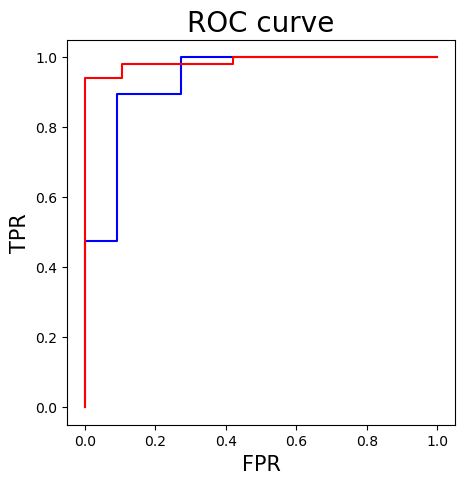

AUC on test = 0.9330


In [17]:
#  生成TPR和FPR
fpr_test, tpr_test, th_test = roc_curve(test['Acc'], test_proba)
fpr_train, tpr_train, th_train = roc_curve(train['Acc'], train_proba)

#  绘制ROC曲线
fig, ax = plt.subplots(figsize=[5, 5])
ax.set_xlabel('FPR',  fontsize=15)
ax.set_ylabel('TPR',  fontsize=15)
ax.plot(fpr_test, tpr_test, 'b-')
ax.plot(fpr_train, tpr_train, 'r-')
plt.title('ROC curve', fontsize=20)
plt.show()

#  打印AUC
print('AUC on test = %6.4f' % auc(fpr_test, tpr_test))

#### 保存预测结果

In [18]:
oos_data.head()

,id,gender,Age,Income,...,dist_home_val,dist_avg_income,high_avg,edu_class
0,95,1,0.575599,0.358904,...,0.492635,0.221384,1.018670,1
1,69,1,-1.249925,-0.348192,...,1.055284,-0.569110,1.767235,1
2,65,0,-0.597952,-0.651233,...,-0.461065,-0.379508,-2.020960,1
3,87,0,1.227571,-0.707681,...,0.725010,-0.607030,-0.682615,1
4,90,1,2.922700,-0.615581,...,-1.668864,-0.624532,0.156685,0


In [19]:
output_data_dir = './data_processed'
if not os.path.exists(output_data_dir):
    os.mkdir(output_data_dir)
output_data_path = os.path.join(output_data_dir,
                               'creditcard_exp_logistic_regression.csv')

oos_data['Pred_Acc'] = lrcv.predict_proba(oos_data[selected_cols])[:,1]
oos_data.to_csv(output_data_path, index=False)

#### 保存和读取模型

In [20]:
import joblib

output_dir = "./model"
if not os.path.exists(output_dir):
    os.mkdir(output_dir)
    
save_path = os.path.join(output_dir, "creditcard_logisticRegression.model")

# 模型持久化
joblib.dump(lrcv, save_path)
# 读取模型
model_reload = joblib.load(save_path)
model_reload.predict(oos_data[selected_cols])

array([1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0], dtype=int64)